# Whole-data coefficient Gram study

Use the coefficient Gram matrix **directly**, divided by full-data n=1692 or
p=110. No mixtures, trace matching, eigenvalue clipping or artificial jitter.
Only slope coefficients enter B; fitted intercepts do not enter the Gram.
The distinction between /n and /p is explicit: they differ by n/p≈15.38.

Delta=1,2,5; both intercept choices; LS or logistic auxiliary loss. Unpenalized
posterior logistic fits: FISTA/L-BFGS/GD, budgets8,16,20,30,50,100. Unpenalized
LS auxiliary fits are exact (not artificially stopped). Penalized fits: matched
L1 or L2 family and strength1e-8,1e-6,1e-5,1e-4,1e-3. Squared loss is residual²,
logistic is log(1+exp(z))-yz; both are weighted means plus the declared penalty.
Intercepts are unpenalized. Logistic/logistic uses the identical fit in both
stages; LS/logistic matches penalty family and numerical strength, not loss.
Convergence-seeking penalized fits report KKT diagnostics; finite budgets apply
only to the unpenalized logistic cases. No raw coefficients are assumed noiseless.

336 model settings × two Gram divisors = **672 comparisons**. Screening uses
512 draws/seed123; finalists use 1024 draws with seeds123 and42. Select the best20
conditional shapes plus leaders within loss/penalty/divisor groups for checks;
rank checked results by mean TV to the earlier rank3 target, without a P(1) cutoff.
36 jobs. Every failure or undefined Gram is reported; no silent repair. State
equations remain heuristic for finite/penalized fits and plug-in Gram estimates.
Numerical checks are not confidence intervals or statistical calibration.

B contains the two original sample-weighted auxiliary regression vectors.


In [1]:
"""Paired whole-data and estimated-segment coefficient Gram experiments."""
from tools.myocardial_final_redo import *
from tools.myocardial_direct_moment_experiment import state_at
from tools.myocardial_best_ones import curve_metrics
from WERM.myocardial_finite_intercept import finite_intercept_column
from WERM.myocardial_no_intercept_solvers import fit_column
from WERM.myocardial_intercept import fit_with_intercept,intercept_loglikelihood
from tools.myocardial_matched_l2_fine import solve_logistic_l2

BASE=Path('results/myocardial_final_redo_e3d965cc4b9b')


def configurations():
    specs=[]
    for d in (1,2,5):
        for intercept in (False,True):
            for aux in ('squared','logistic'):
                for method in ('fista','lbfgs','gd'):
                    for budget in (8,16,20,30,50,100):
                        specs.append(dict(Delta=d,intercept=intercept,aux_loss=aux,
                            penalty='none',strength=0.,method=method,budget=budget))
                for penalty in ('l1','l2'):
                    for strength in (1e-8,1e-6,1e-5,1e-4,1e-3):
                        specs.append(dict(Delta=d,intercept=intercept,aux_loss=aux,
                            penalty=penalty,strength=strength,method='full',budget=0))
    for i,s in enumerate(specs):s['id']=f'config{i:03d}'
    return specs


def column(X,y,w,spec,loss):
    n,p=X.shape;intercept=spec['intercept'];family=spec['penalty'];strength=spec['strength']
    if loss=='logistic' and family=='none':
        if intercept:return finite_intercept_column(X,y,w,spec['method'],spec['budget'])
        return fit_column(X,y,w,spec['method'],spec['budget'])
    if loss=='logistic' and family=='l2' and not intercept:
        r=solve_logistic_l2(X,y,w,strength);return dict(r,intercept=0.)
    if loss=='logistic' and intercept:
        r=fit_with_intercept(X,y,np.array([w]),family,strength)
        return dict(coef=r['coef'][:,0],intercept=float(r['intercepts'][0]),**r['checks'][0])
    design=np.column_stack([X,np.ones(n)]) if intercept else X
    r=fit_weighted(design,y,sample_weight=w,loss=loss,loss_scale=2. if loss=='squared' else 1.,
        penalty=family,penalty_strength=strength,unpenalized_indices=[p] if intercept else [],
        max_iter=30000,tol=1e-8)
    return dict(coef=r.coef[:p],intercept=float(r.coef[p]) if intercept else 0.,
                kkt=r.kkt_violation,success=r.converged,iterations=r.n_iter)


def fit(X,y,phi,spec,loss):
    cols=[column(X,y,w,spec,loss) for w in phi]
    B=np.column_stack([c['coef'] for c in cols]);alpha=np.array([c.get('intercept',0.) for c in cols])
    theta=X@B+alpha;adjusted,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss=loss)
    V=adjusted-(X.mean(axis=0)@B+alpha) if spec['intercept'] else adjusted
    return dict(coef=B,theta=theta,V=V,b=b,intercepts=alpha,checks=cols)


def prepare(spec,X,y,locations,root):
    path=root/(spec['id']+'_fits.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    try:
        d=spec['Delta'];eta,prior,phi=configuration_prior(len(y),locations[(locations>=d)&(locations<=len(y)-d)])
        auxiliary=fit(X,y,phi,spec,spec['aux_loss'])
        posterior=auxiliary if spec['aux_loss']=='logistic' else fit(X,y,phi,spec,'logistic')
        e,psi=pilot(auxiliary['theta'],y,eta,spec['aux_loss'])
        result=dict(spec=spec,setting=dict(eta=eta,prior=prior,phi=phi),auxiliary=auxiliary,
            posterior=posterior,pilot=e,psi=psi,loss=spec['aux_loss'],delta=len(y)/X.shape[1],rate=float(y.mean()))
    except Exception:result=dict(error=traceback.format_exc(),spec=spec)
    atomic_save(path,result);return result


def balanced_segment_weights(y):
    y=np.asarray(y)
    if not np.all(np.isin(y,[0,1])) or len(np.unique(y))!=2:
        raise ValueError('Balanced segment requires both binary classes')
    counts=np.bincount(y.astype(int),minlength=2)
    return len(y)/(2*counts[y.astype(int)])


def gram_coefficients(prepared,X,y,mode,root):
    if mode=='whole':return prepared['auxiliary']['coef']
    path=root/(prepared['spec']['id']+'_segment_coefficients.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    e=prepared['pilot']
    if not 0<e<len(y):raise ValueError('No pilot change point: segment Gram undefined')
    spec=prepared['spec'];columns=[]
    for segment in (slice(None,e),slice(e,None)):
        Xi,yi=X[segment],y[segment]
        w=balanced_segment_weights(yi) if mode=='segmented_balanced' else np.ones(len(yi))
        c=column(Xi,yi,w,spec,spec['aux_loss']);columns.append(c)
    B=np.column_stack([c['coef'] for c in columns])
    atomic_save(path,B);atomic_save(root/(spec['id']+'_segment_checks.pkl'),columns)
    return B


def evaluate(prepared,X,y,ages,mode,denominator,root,power=9,seed=123):
    ident=prepared['spec']['id']+'_'+denominator
    path=root/f'{ident}_p{power}s{seed}.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    partial=root/f'{ident}_p{power}s{seed}_partial.pkl'
    try:
        spec=prepared['spec'];B=gram_coefficients(prepared,X,y,mode,root)
        divisor=len(y) if denominator=='n' else X.shape[1]
        rho=B.T@B/divisor;eigenvalues=np.linalg.eigvalsh(rho)
        if eigenvalues.min()<=0 or eigenvalues.min()<1e-12*eigenvalues.max():
            raise ValueError('Singular/numerically rank-deficient Gram: no jitter, clipping or repair applied')
        states=pickle.load(partial.open('rb')) if partial.exists() else []
        eta=prepared['setting']['eta'];n=len(y)
        for e in eta[len(states):]:
            psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
            states.append(state_at(prepared,rho,psi,power=power,seed=seed,loss='logistic'))
            if len(states)%8==0:atomic_save(partial,states)
        atomic_save(partial,states);values=[]
        for e,state in zip(eta,states):
            psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
            if spec['intercept']:ll=intercept_loglikelihood(prepared['posterior']['V'],y,rho,state,psi,order=160)
            else:ll=gaussian_logistic_loglikelihood(prepared['posterior']['V'],y,rho,state['lambda'],state['kappa'],psi,quadrature_order=160)
            values.append(ll)
        result=normalize_posterior(values,prepared['setting']['prior']);a=ages[eta[1:]]
        target=pickle.load((BASE/'scenario_100_100_q10_seed123.pkl').open('rb'))
        metrics=curve_metrics(a,result['conditional'],dict(zip(target['ages'],target['conditional'])))
        result.update(spec,id=ident,mode=mode,denominator=denominator,rho=rho,ages=a,
            pilot=prepared['pilot'],pilot_age=ages[prepared['pilot']] if prepared['pilot']>=0 else np.nan,
            P_1=result['presence'],TV_to_rank3=metrics['TV'],peak_age=metrics['peak'],mass_above55=metrics['above55'],
            correlation=rho[0,1]/np.sqrt(rho[0,0]*rho[1,1]),rho_11=rho[0,0],rho_12=rho[0,1],rho_22=rho[1,1],
            max_state_residual=max(s['training_residual'] for s in states),power=power,seed=seed,checkpoint=str(path),
            max_aux_kkt=max(c.get('kkt',np.nan) for c in prepared['auxiliary']['checks']),
            max_post_kkt=max(c.get('kkt',np.nan) for c in prepared['posterior']['checks']))
    except Exception:result=dict(error=traceback.format_exc(),id=ident,spec=prepared['spec'],mode=mode,power=power,seed=seed)
    atomic_save(path,result);return result


def table(rows):
    return pd.DataFrame([{k:v for k,v in r.items() if k not in ('rho','ages','conditional','probabilities','log_likelihood')}
        for r in rows if 'error' not in r])


def run(mode='whole',smoke=False):
    if mode not in ('whole','segmented','segmented_balanced'):raise ValueError(mode)
    X,y,ages,locations=load_data();specs=configurations()
    fingerprint=hashlib.sha256(Path('tools/myocardial_gram_comparison.py').read_bytes()).hexdigest()[:12]
    shared=Path('results')/('myocardial_gram_pair_'+fingerprint);shared.mkdir(exist_ok=True)
    root=shared/mode;root.mkdir(exist_ok=True)
    (shared/'specification.json').write_text(json.dumps(dict(configurations=specs,normalizations=['n','p'],
        primary_draws=512,final_draws=1024,final_seeds=[123,42],coefficient_gram='slopes only, intercept excluded',
        segmented='same pilot auxiliary loss, solver, penalty; full-data n or p divisor, no segment rewhitening',
        penalty_matching='same family and strength in auxiliary and posterior; squared loss scale=2'),indent=2))
    if smoke:
        chosen=[dict(specs[0],id='smoke_ls'),dict(next(s for s in specs if s['aux_loss']=='logistic' and s['intercept']),id='smoke_logistic')]
        for spec in chosen:
            p=prepare(spec,X,y,locations,shared)
            assert 'error' not in p,p
            B=gram_coefficients(p,X,y,mode,root)
            assert B.shape==(X.shape[1],2)
            for denom in ('n','p'):assert np.linalg.eigvalsh(B.T@B/(len(y) if denom=='n' else X.shape[1])).min()>0
        print('Gram fit and',mode,'segment checks passed; configurations:',len(specs)*2,flush=True);return root
    with parallel_config(backend='loky',inner_max_num_threads=1):
        prepared=Parallel(n_jobs=36)(delayed(prepare)(s,X,y,locations,shared) for s in specs)
        # Segment coefficients are populated once per setting before the two
        # normalization tasks, preventing competing writes to their checkpoint.
    errors=[p for p in prepared if 'error' in p]
    valid=[]
    for p in prepared:
        if 'error' in p:continue
        if mode!='whole':
            try:gram_coefficients(p,X,y,mode,root)
            except Exception:
                errors.append(dict(id=p['spec']['id'],error=traceback.format_exc()));continue
        valid.append(p)
    with parallel_config(backend='loky',inner_max_num_threads=1):
        results=Parallel(n_jobs=36)(delayed(evaluate)(p,X,y,ages,mode,d,root) for p in valid for d in ('n','p'))
    errors += [r for r in results if 'error' in r]
    summary=table(results);summary.to_csv(root/'summary.csv',index=False)
    selected=pd.concat([summary.sort_values('TV_to_rank3').head(20),
        summary.sort_values('TV_to_rank3').groupby(['aux_loss','penalty','denominator']).head(2)]).drop_duplicates('id')
    selected.to_csv(root/'selected_for_validation.csv',index=False)
    mapping={p['spec']['id']:p for p in valid}
    with parallel_config(backend='loky',inner_max_num_threads=1):
        checked=Parallel(n_jobs=36)(delayed(evaluate)(mapping[row.id.rsplit('_',1)[0]],X,y,ages,mode,row.denominator,root,10,seed)
            for row in selected.itertuples() for seed in (123,42))
    errors += [r for r in checked if 'error' in r];table(checked).to_csv(root/'validation.csv',index=False)
    ranked=[]
    for ident in selected.id:
        pair=[r for r in checked if r['id']==ident and 'error' not in r]
        if len(pair)!=2:continue
        a,b=pair;row=table([a]).iloc[0].to_dict()
        row.update(mean_TV_to_rank3=(a['TV_to_rank3']+b['TV_to_rank3'])/2,P1_min=min(a['P_1'],b['P_1']),
            P1_max=max(a['P_1'],b['P_1']),numerical_TV=.5*np.abs(a['conditional']-b['conditional']).sum(),check_checkpoint=b['checkpoint'])
        ranked.append(row)
    ranked=pd.DataFrame(ranked).sort_values('mean_TV_to_rank3');ranked.insert(0,'rank',np.arange(1,len(ranked)+1))
    ranked.to_csv(root/'ranked.csv',index=False);ranked.head(20).to_csv(root/'top_twenty.csv',index=False)
    (root/'errors.json').write_text(json.dumps(errors,indent=2,default=str))
    if mode!='whole' and (shared/'whole'/'summary.csv').exists():
        whole=pd.read_csv(shared/'whole'/'summary.csv')
        summary.merge(whole,on='id',suffixes=('_segmented','_whole')).to_csv(root/'paired_whole_vs_segmented.csv',index=False)
    print('GRAM STUDY COMPLETE',mode,root,flush=True);return root




/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
root=run('whole')
print(root)

GRAM STUDY COMPLETE whole results/myocardial_gram_pair_1ce06b10b4f5/whole


results/myocardial_gram_pair_1ce06b10b4f5/whole


All tested outcomes:


,presence,absence,Delta,intercept,aux_loss,penalty,strength,method,budget,id,...,correlation,rho_11,rho_12,rho_22,max_state_residual,power,seed,checkpoint,max_aux_kkt,max_post_kkt
0,1.000000,8.909555e-24,1,False,squared,none,0.00000,fista,8,config000_n,...,0.925832,0.025592,0.026603,0.032261,1.132120e-09,9,123,results/myocardial_gram_pair_1ce06b10b4f5/whol...,3.076424e-18,2.052392e-04
1,1.000000,5.011935e-48,1,False,squared,none,0.00000,fista,8,config000_p,...,0.925832,0.393657,0.409198,0.496232,6.790932e-10,9,123,results/myocardial_gram_pair_1ce06b10b4f5/whol...,3.076424e-18,2.052392e-04
2,1.000000,2.503585e-121,1,False,squared,none,0.00000,fista,16,config001_n,...,0.925832,0.025592,0.026603,0.032261,1.132120e-09,9,123,results/myocardial_gram_pair_1ce06b10b4f5/whol...,3.076424e-18,1.901676e-04
3,1.000000,0.000000e+00,1,False,squared,none,0.00000,fista,16,config001_p,...,0.925832,0.393657,0.409198,0.496232,6.790932e-10,9,123,results/myocardial_gram_pair_1ce06b10b4f5/whol...,3.076424e-18,1.901676e-04
4,1.000000,3.788974e-237,1,False,squared,none,0.00000,fista,20,config002_n,...,0.925832,0.025592,0.026603,0.032261,1.132120e-09,9,123,results/myocardial_gram_pair_1ce06b10b4f5/whol...,3.076424e-18,1.803467e-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
667,1.000000,1.188554e-20,5,True,logistic,l2,0.00001,full,0,config333_p,...,0.962890,10.614694,9.672679,9.506759,3.651860e-10,9,123,results/myocardial_gram_pair_1ce06b10b4f5/whol...,2.982834e-09,2.982834e-09
668,0.905182,9.481814e-02,5,True,logistic,l2,0.00010,full,0,config334_n,...,0.954674,0.097167,0.092133,0.095852,6.740107e-10,9,123,results/myocardial_gram_pair_1ce06b10b4f5/whol...,3.865134e-11,3.865134e-11
669,0.999985,1.504537e-05,5,True,logistic,l2,0.00010,full,0,config334_p,...,0.954674,1.494613,1.417176,1.474378,1.205868e-10,9,123,results/myocardial_gram_pair_1ce06b10b4f5/whol...,3.865134e-11,3.865134e-11
670,0.453171,5.468293e-01,5,True,logistic,l2,0.00100,full,0,config335_n,...,0.945568,0.002062,0.002037,0.002251,7.193439e-10,9,123,results/myocardial_gram_pair_1ce06b10b4f5/whol...,1.229152e-09,1.229152e-09


Top20:


rank,presence,absence,Delta,intercept,aux_loss,penalty,strength,method,budget,id,mode,denominator,pilot,pilot_age,P_1,TV_to_rank3,peak_age,mass_above55,correlation,rho_11,rho_12,rho_22,max_state_residual,power,seed,checkpoint,max_aux_kkt,max_post_kkt,mean_TV_to_rank3,P1_min,P1_max,numerical_TV,check_checkpoint
1,0.28504,0.71496,5,True,squared,none,0.00000,fista,30,config283_p,whole,p,1127,67.00000,0.28504,0.23100,79.00000,1.00000,0.96240,0.42022,0.39077,0.39234,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/whole/config283_p_p10s123.pkl,0.00000,0.00000,0.23126,0.28504,0.28626,0.00185,results/myocardial_gram_pair_1ce06b10b4f5/whole/config283_p_p10s42.pkl
2,0.28040,0.71960,2,True,squared,none,0.00000,fista,30,config171_p,whole,p,1127,67.00000,0.28040,0.23175,81.00000,1.00000,0.96704,0.41914,0.39224,0.39252,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/whole/config171_p_p10s123.pkl,0.00000,0.00000,0.23206,0.28040,0.28173,0.00227,results/myocardial_gram_pair_1ce06b10b4f5/whole/config171_p_p10s42.pkl
3,0.27345,0.72655,1,True,squared,none,0.00000,fista,30,config059_p,whole,p,1127,67.00000,0.27345,0.23473,81.00000,1.00000,0.96876,0.41898,0.39291,0.39260,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/whole/config059_p_p10s123.pkl,0.00000,0.00000,0.23505,0.27345,0.27481,0.00237,results/myocardial_gram_pair_1ce06b10b4f5/whole/config059_p_p10s42.pkl
4,0.15144,0.84856,5,False,squared,l1,0.00100,full,0,config246_p,whole,p,924,64.00000,0.15144,0.24769,85.00000,1.00000,0.81871,0.06404,0.06265,0.09143,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/whole/config246_p_p10s123.pkl,0.00000,0.00000,0.25176,0.14721,0.15144,0.01079,results/myocardial_gram_pair_1ce06b10b4f5/whole/config246_p_p10s42.pkl
5,0.16682,0.83318,5,True,squared,none,0.00000,fista,50,config284_p,whole,p,1127,67.00000,0.16682,0.26332,85.00000,1.00000,0.96240,0.42022,0.39077,0.39234,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/whole/config284_p_p10s123.pkl,0.00000,0.00000,0.26275,0.16682,0.16747,0.00147,results/myocardial_gram_pair_1ce06b10b4f5/whole/config284_p_p10s42.pkl
6,0.16719,0.83281,1,False,squared,l1,0.00100,full,0,config022_p,whole,p,924,64.00000,0.16719,0.26840,85.00000,1.00000,0.83926,0.06402,0.06283,0.08754,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/whole/config022_p_p10s123.pkl,0.00000,0.00000,0.27209,0.16362,0.16719,0.01003,results/myocardial_gram_pair_1ce06b10b4f5/whole/config022_p_p10s42.pkl
7,0.16856,0.83144,2,False,squared,l1,0.00100,full,0,config134_p,whole,p,924,64.00000,0.16856,0.27036,85.00000,1.00000,0.83304,0.06403,0.06278,0.08871,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/whole/config134_p_p10s123.pkl,0.00000,0.00000,0.27425,0.16487,0.16856,0.01029,results/myocardial_gram_pair_1ce06b10b4f5/whole/config134_p_p10s42.pkl
8,0.17803,0.82197,1,True,squared,none,0.00000,fista,50,config060_p,whole,p,1127,67.00000,0.17803,0.28205,85.00000,1.00000,0.96876,0.41898,0.39291,0.39260,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/whole/config060_p_p10s123.pkl,0.00000,0.00000,0.28137,0.17803,0.17873,0.00178,results/myocardial_gram_pair_1ce06b10b4f5/whole/config060_p_p10s42.pkl
9,0.18108,0.81892,2,True,squared,none,0.00000,fista,50,config172_p,whole,p,1127,67.00000,0.18108,0.28217,85.00000,1.00000,0.96704,0.41914,0.39224,0.39252,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/whole/config172_p_p10s123.pkl,0.00000,0.00000,0.28150,0.18108,0.18176,0.00172,results/myocardial_gram_pair_1ce06b10b4f5/whole/config172_p_p10s42.pkl
10,0.16543,0.83457,5,False,squared,l2,0.00010,full,0,config250_n,whole,n,1127,67.00000,0.16543,0.30723,88.00000,0.99999,0.91376,0.01854,0.01944,0.02441,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/whole/config250_n_p10s123.pkl,0.00000,0.00000,0.30659,0.16337,0.16543,0.00583,results/myocardial_gram_pair_1ce06b10b4f5/whole/config250_n_p10s42.pkl


Errors/non-evaluable settings:


[]

### #1: config283_p

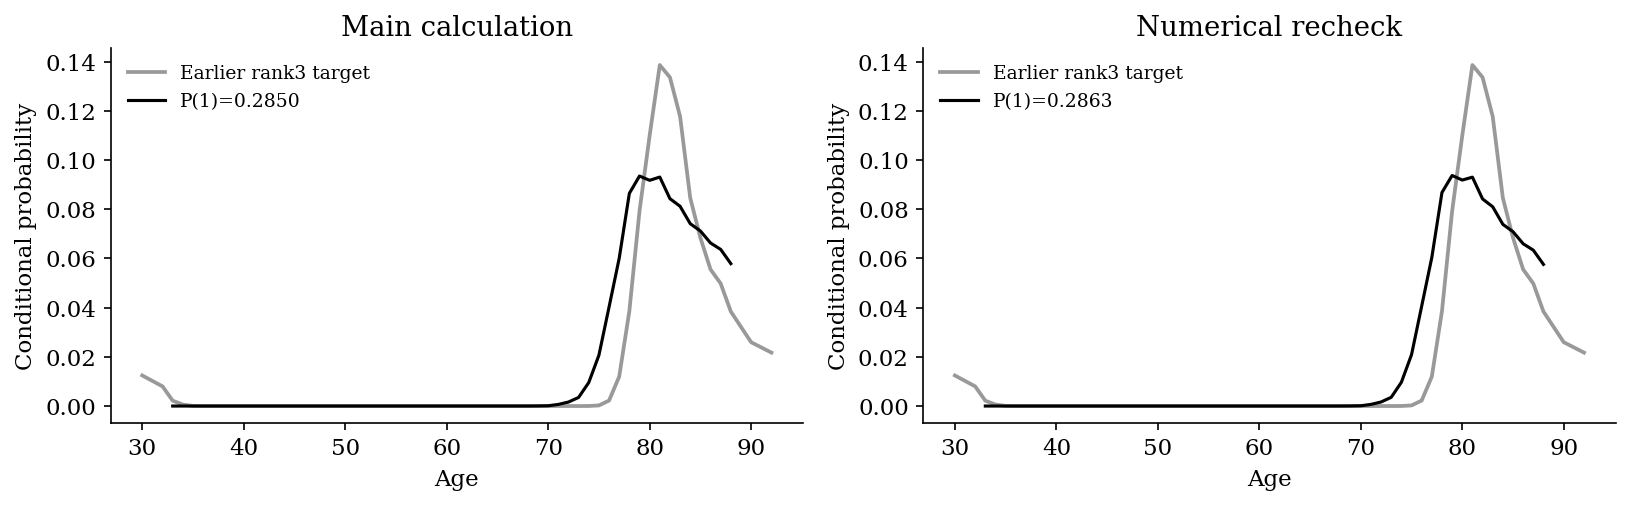

### #2: config171_p

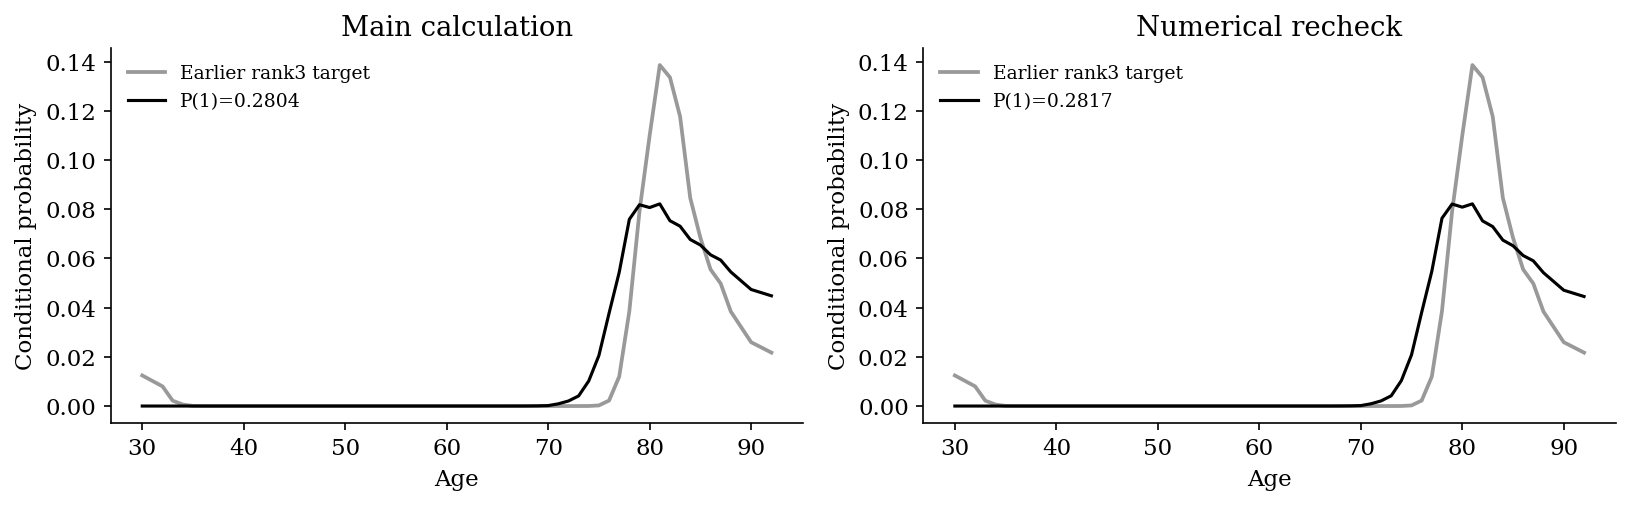

### #3: config059_p

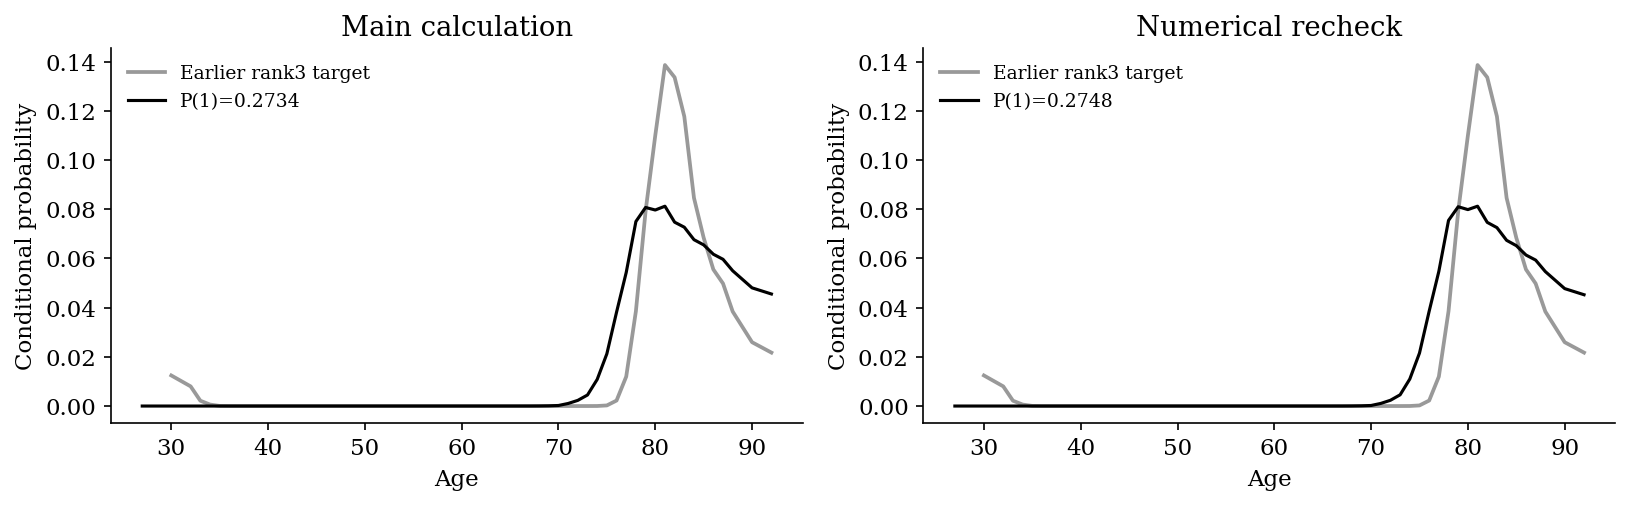

### #4: config246_p

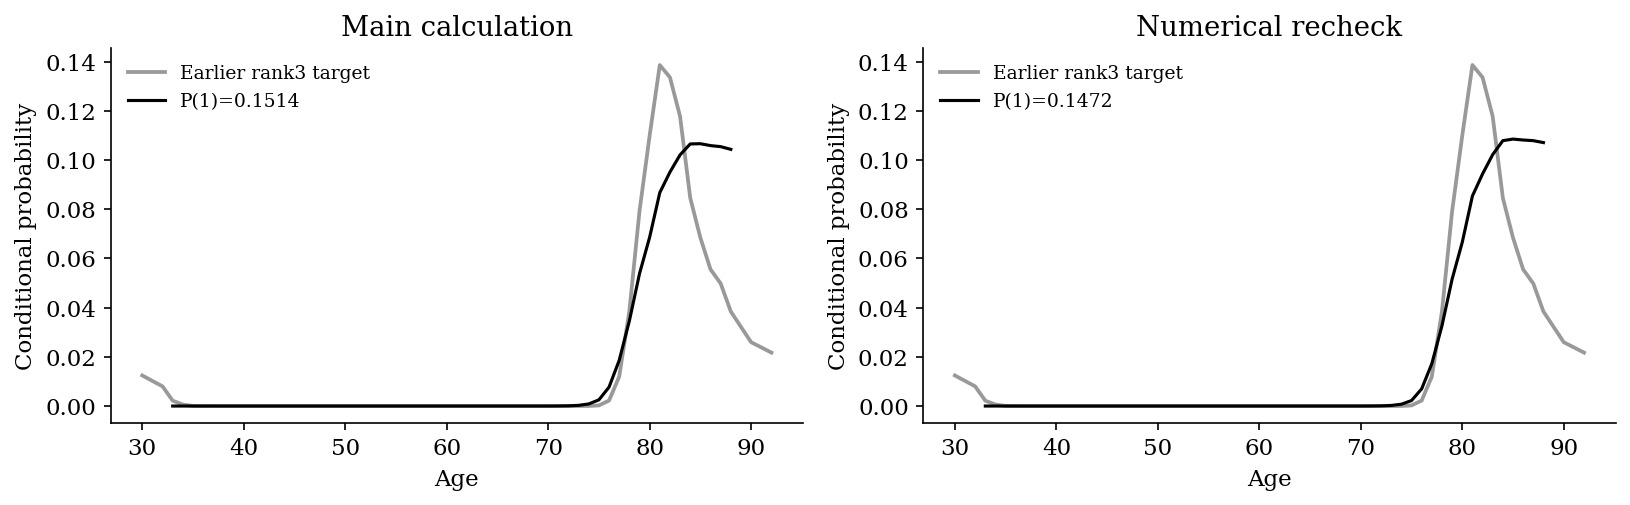

### #5: config284_p

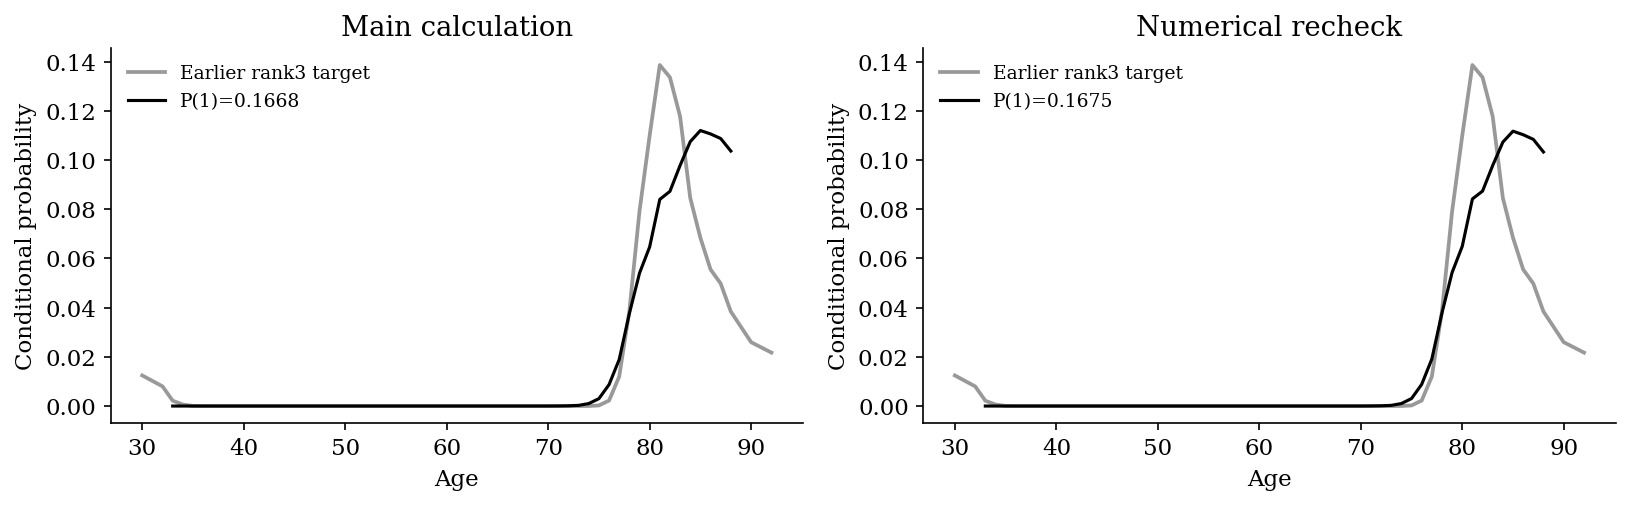

### #6: config022_p

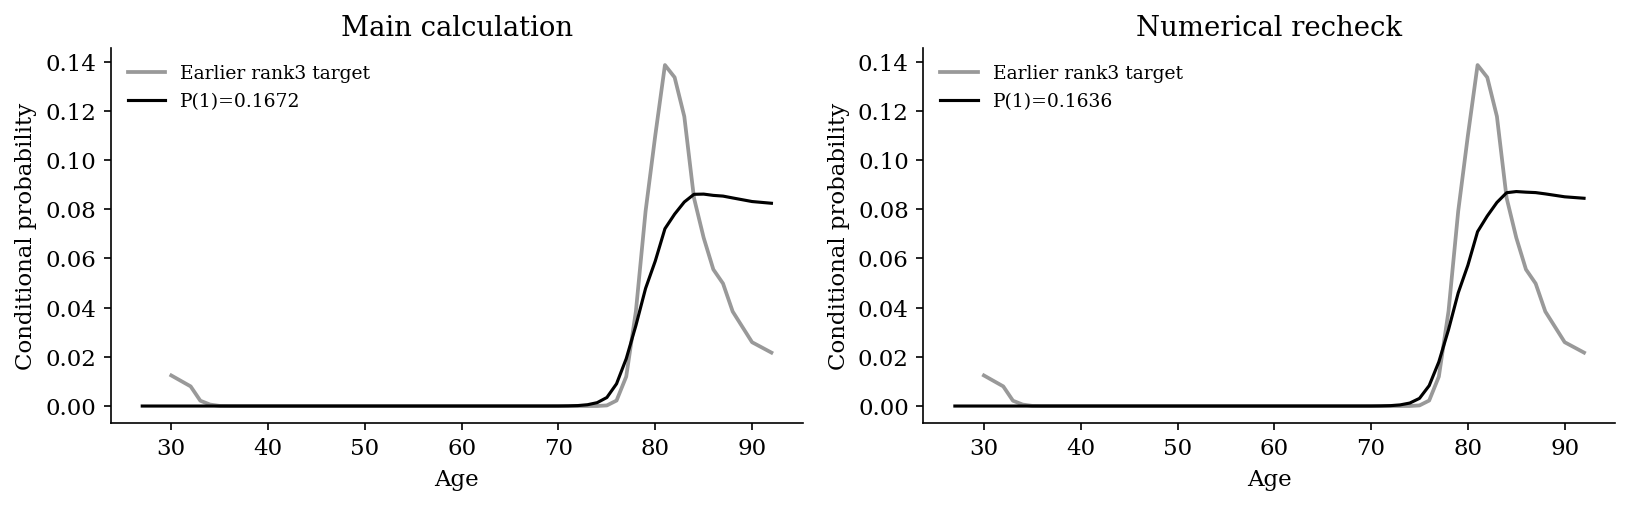

### #7: config134_p

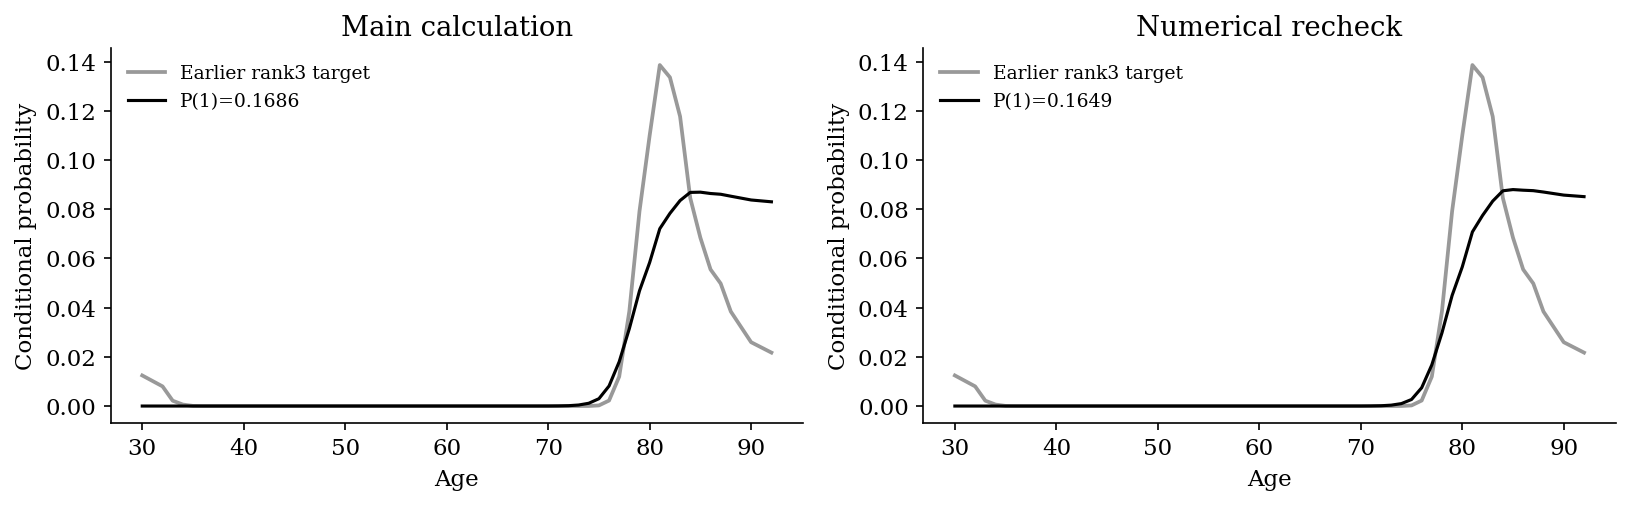

### #8: config060_p

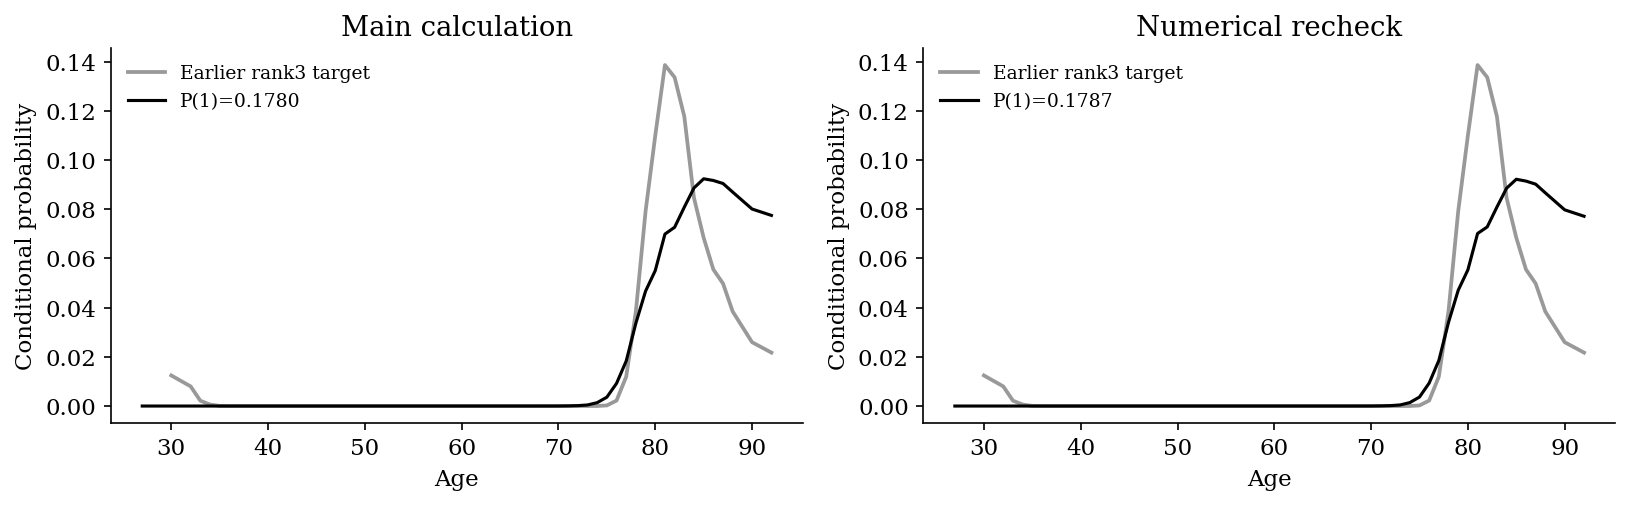

### #9: config172_p

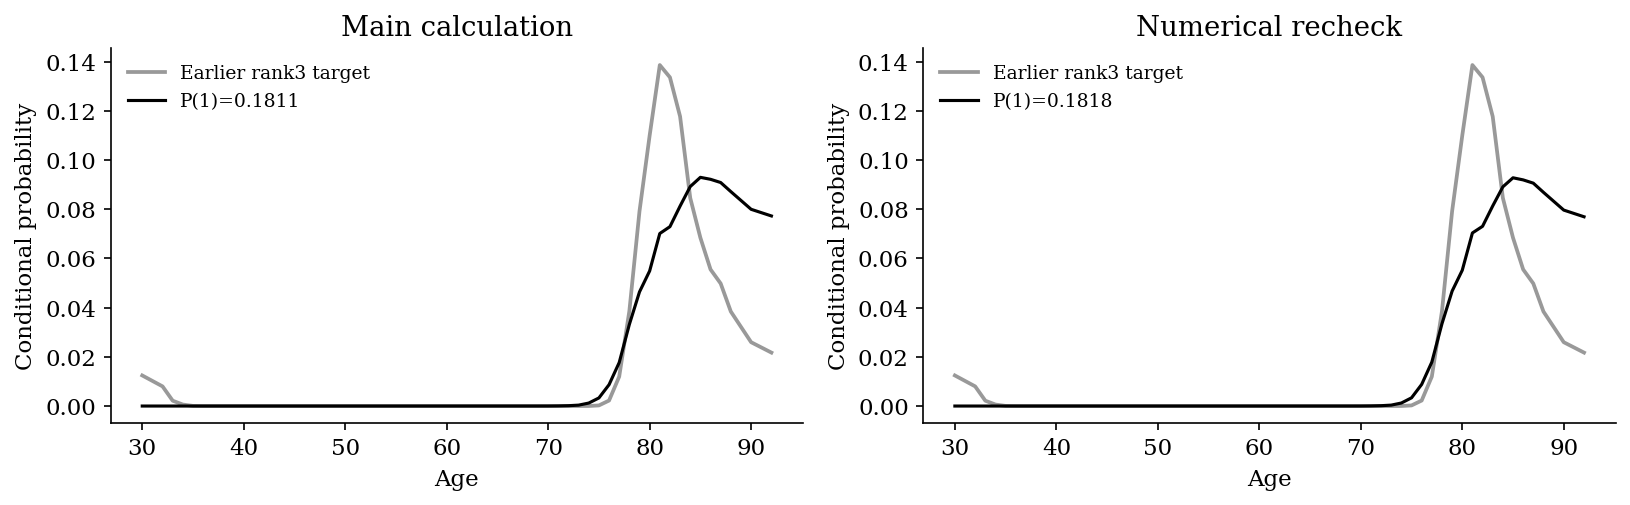

### #10: config250_n

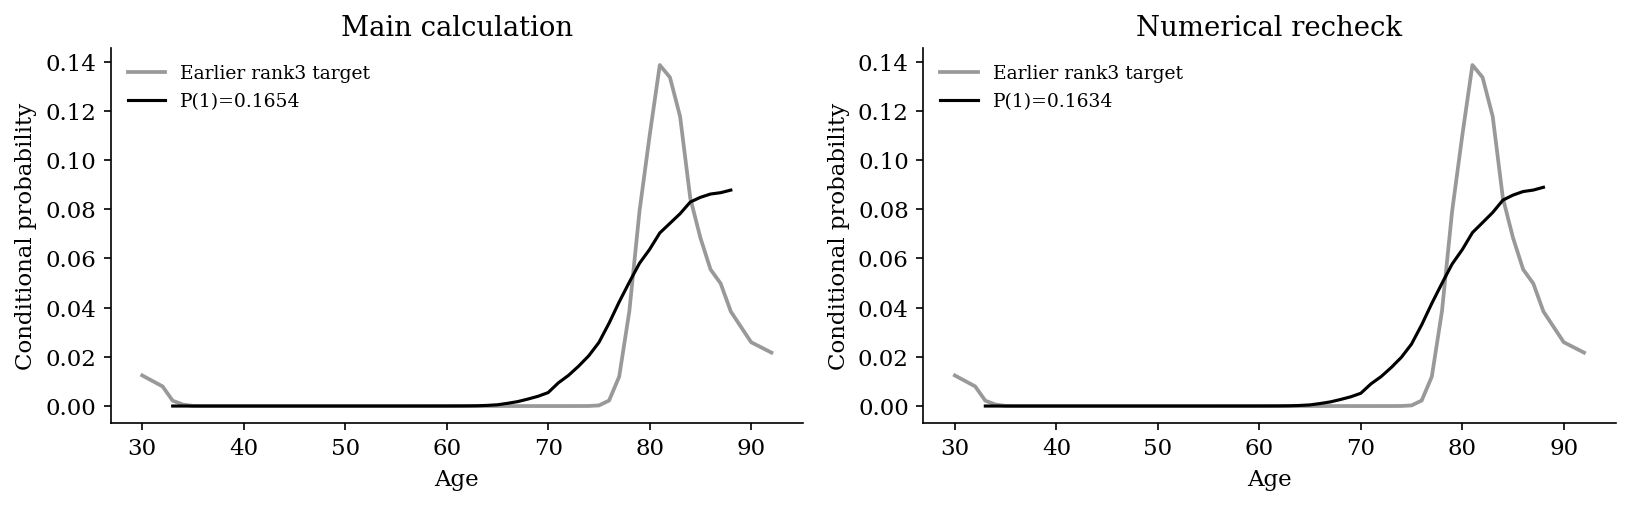

### #11: config281_n

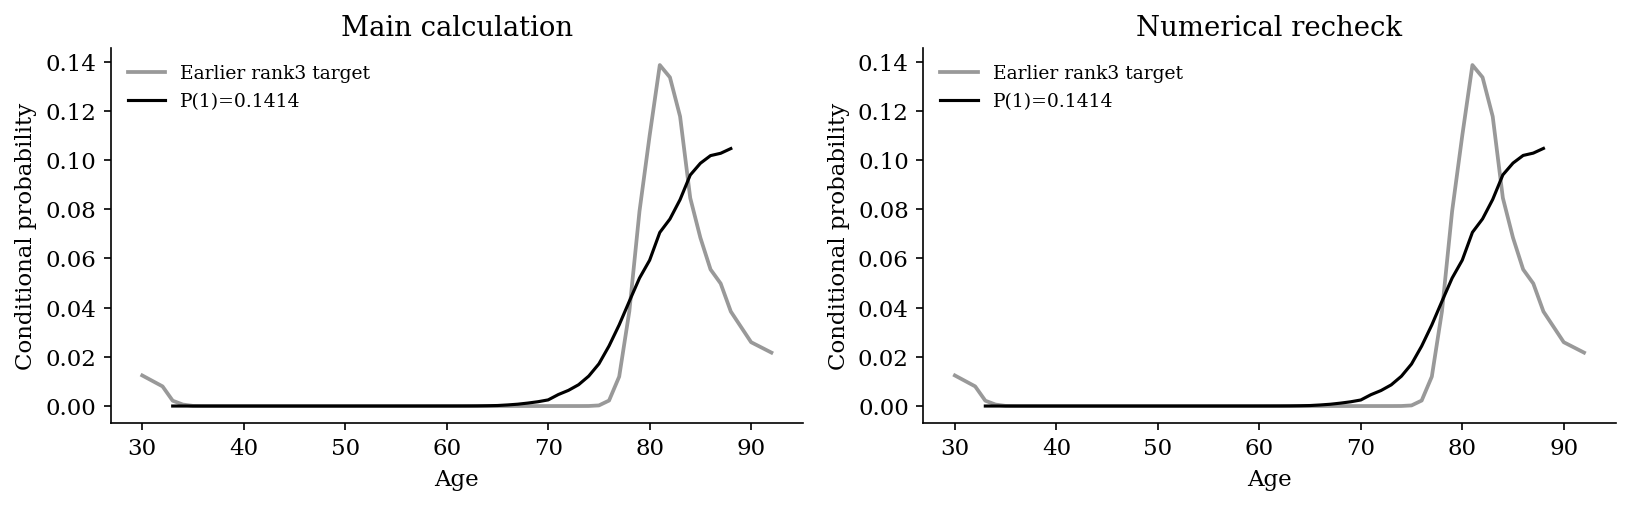

### #12: config296_n

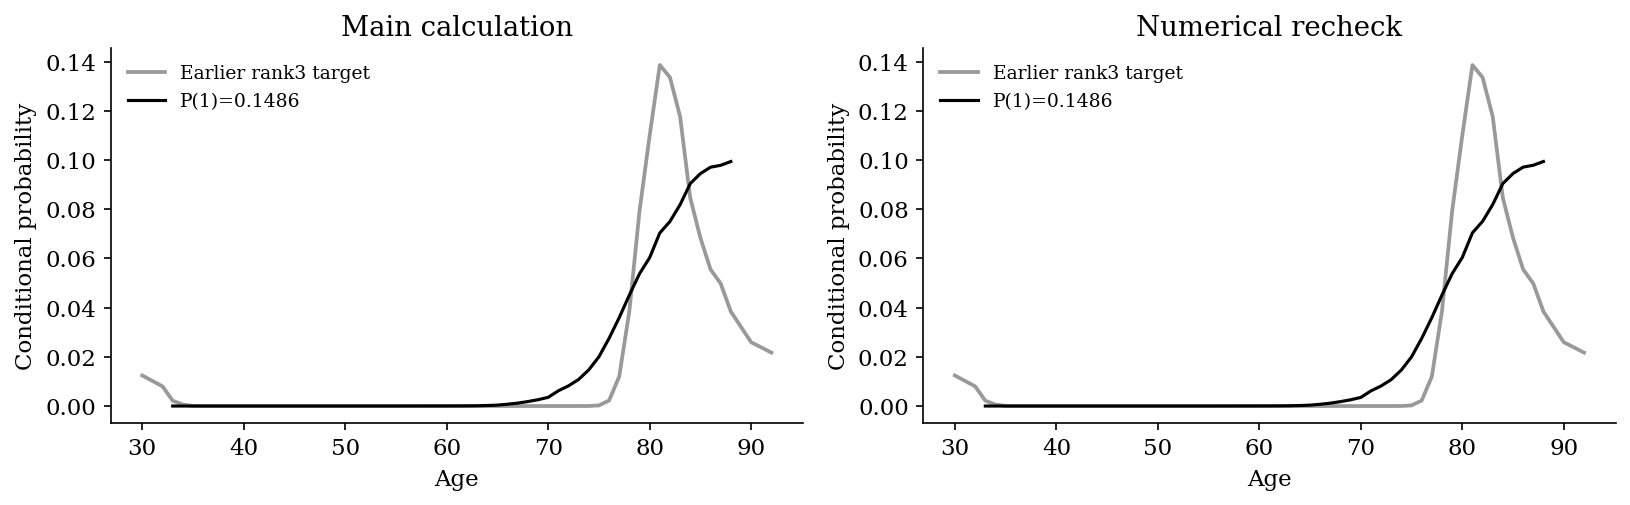

### #13: config297_n

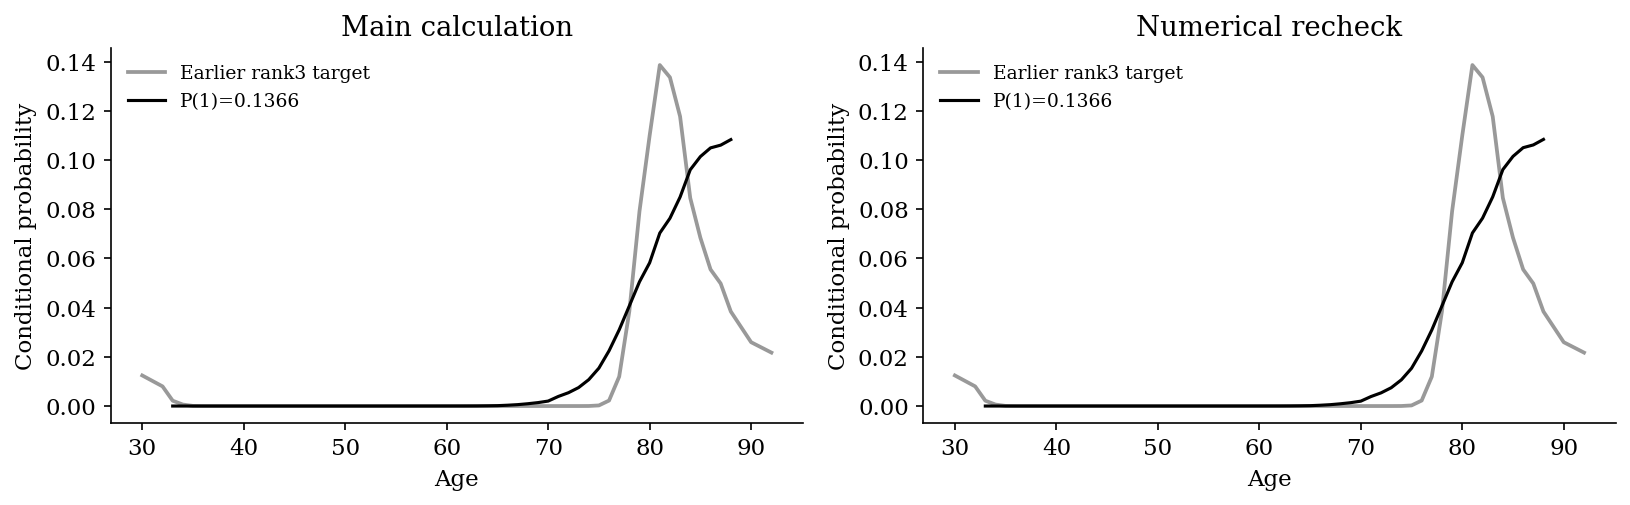

### #14: config282_n

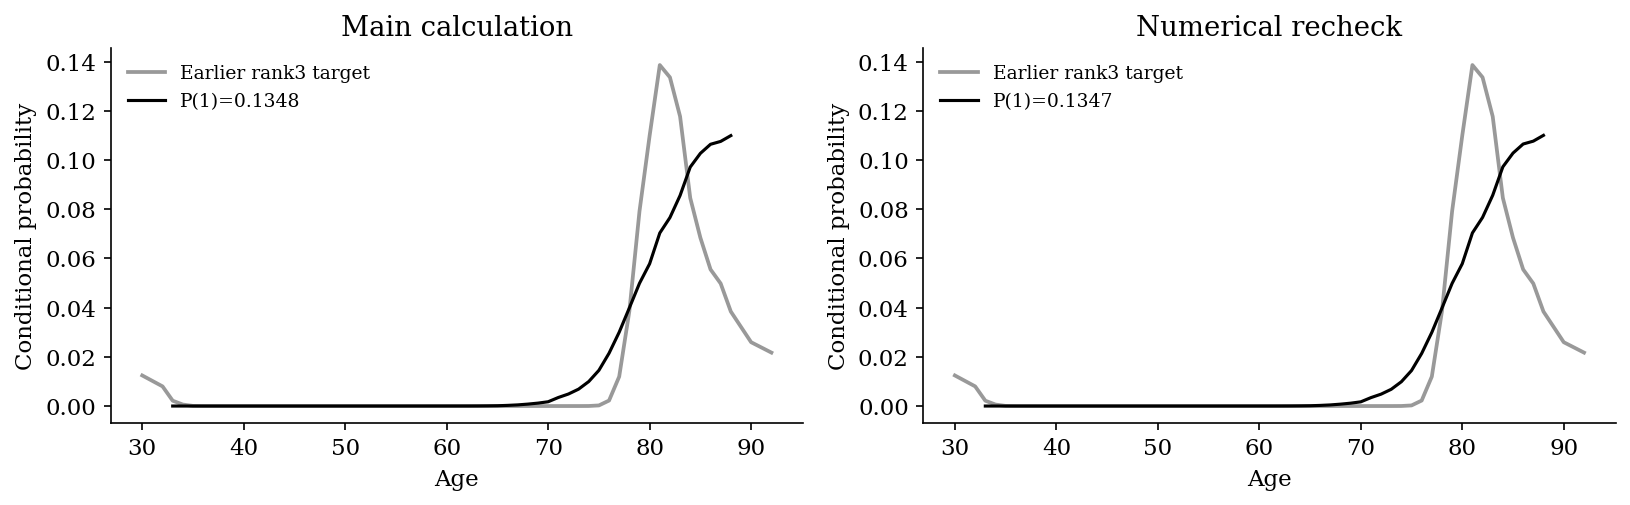

### #15: config286_n

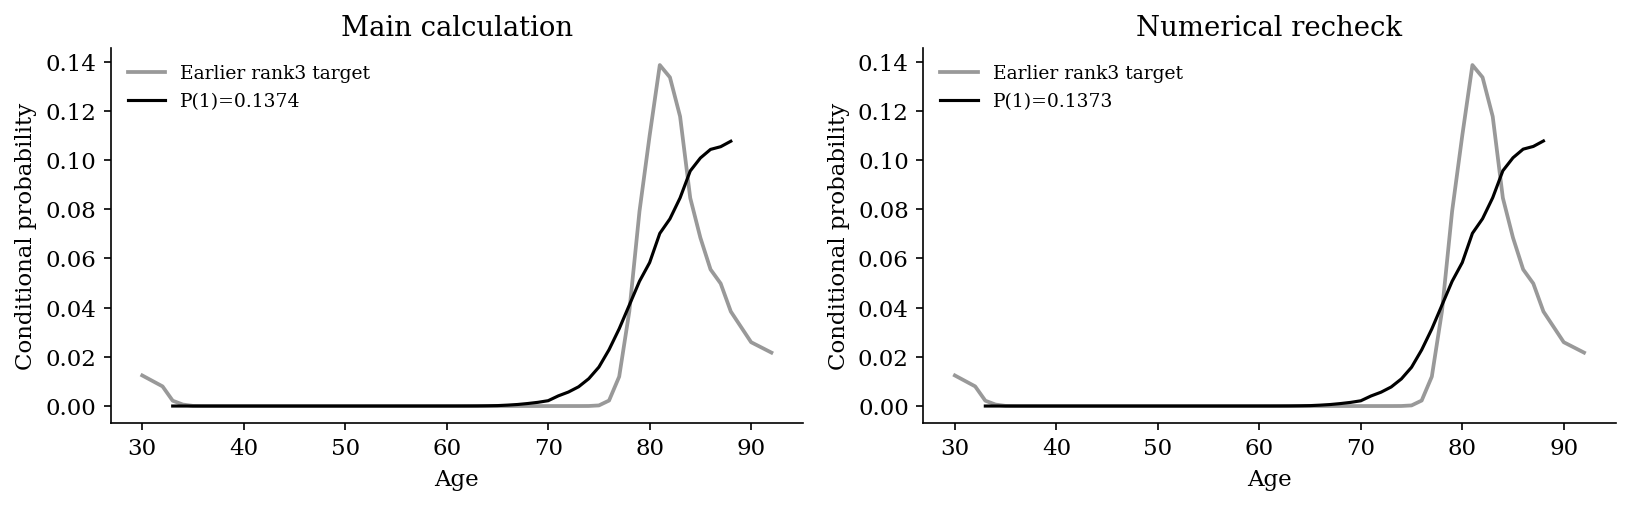

### #16: config295_n

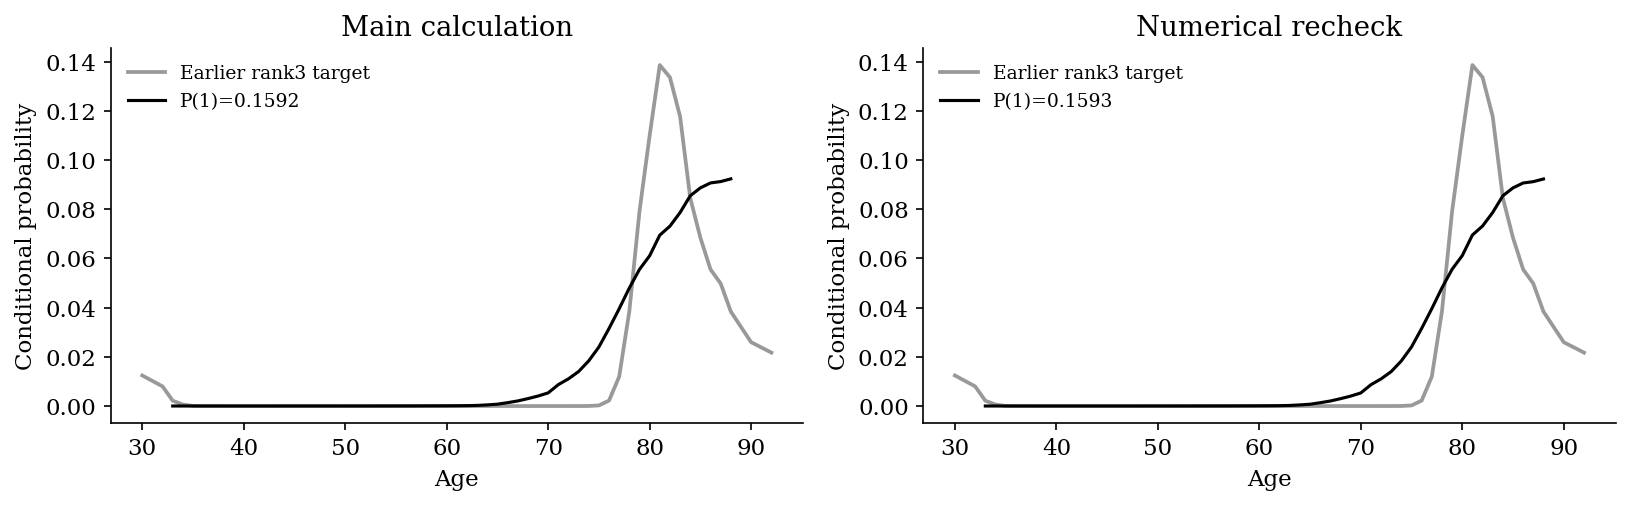

### #17: config300_n

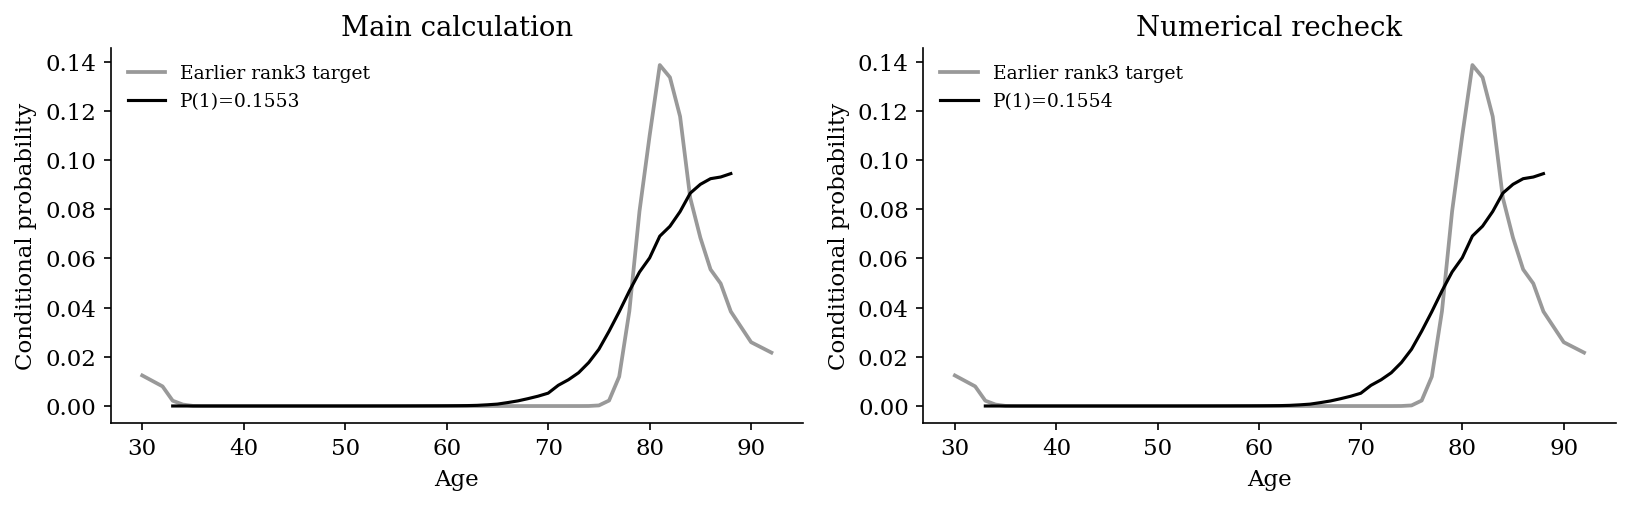

### #18: config304_n

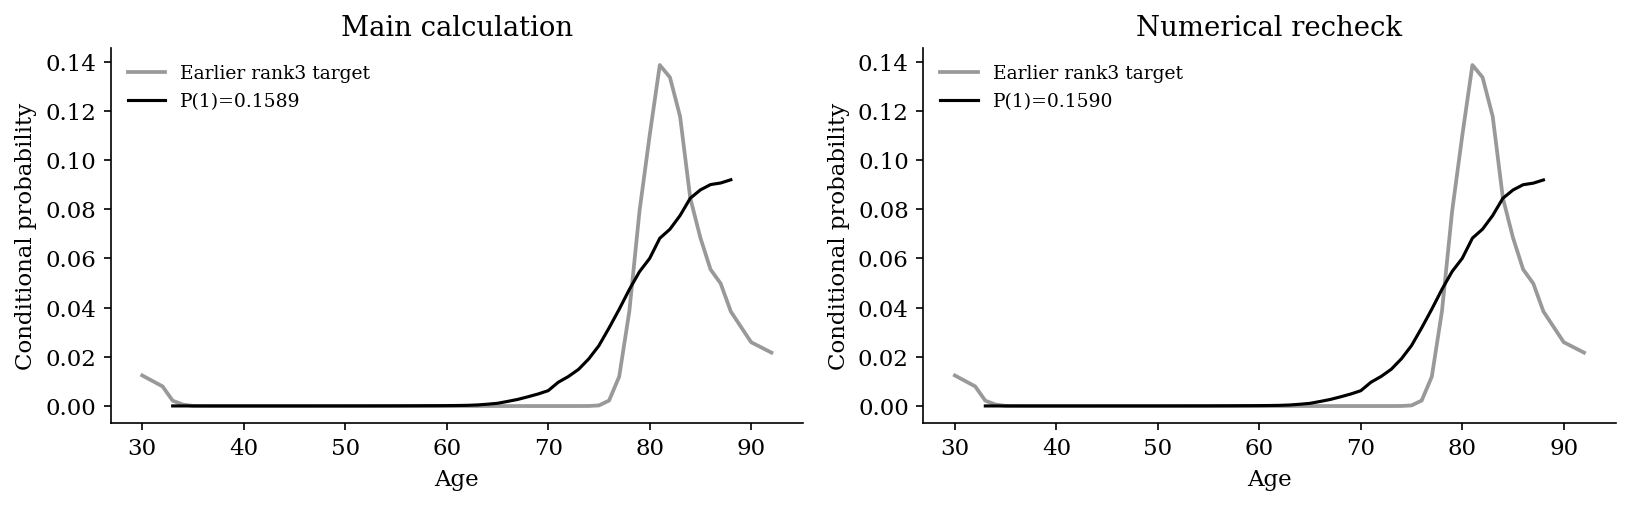

### #19: config294_n

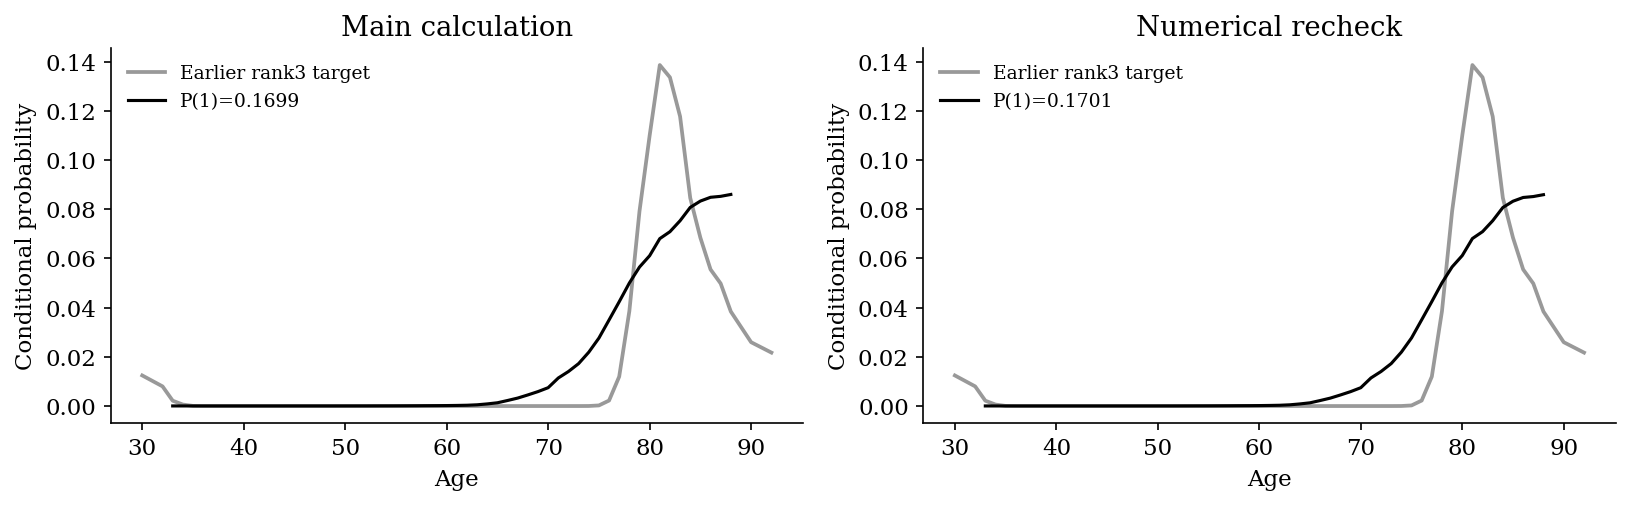

### #20: config283_n

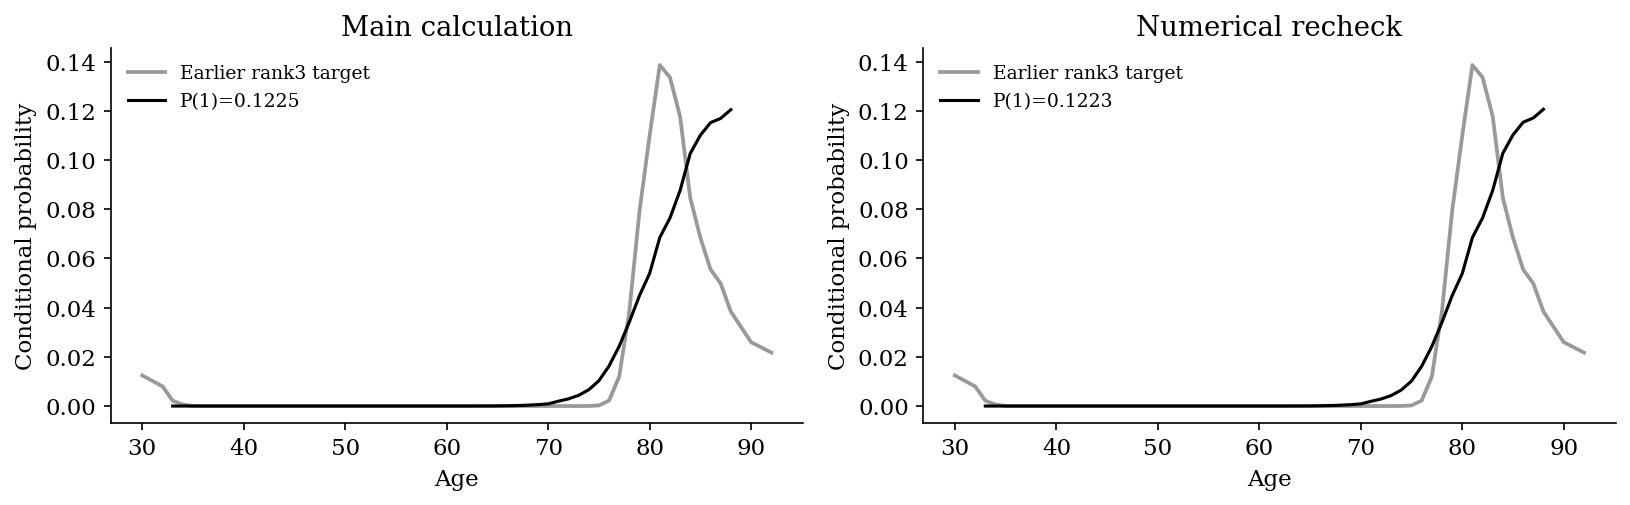

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
summary=pd.read_csv(root/'summary.csv');ranked=pd.read_csv(root/'ranked.csv')
print('All tested outcomes:');display(summary)
print('Top20:');display(ranked.head(20).style.hide(axis='index').format(precision=5))
print('Errors/non-evaluable settings:');display(json.loads((root/'errors.json').read_text()))
target=pickle.load((BASE/'scenario_100_100_q10_seed123.pkl').open('rb'))
def load_result(path,ident):
    saved=pickle.load(open(path,'rb'))
    return next(r for r in saved['results'] if r['id']==ident) if 'results' in saved else saved
for row in ranked.head(20).itertuples():
    a=load_result(row.checkpoint,row.id);b=load_result(row.check_checkpoint,row.id)
    display(Markdown(f'### #{row.rank}: {row.id}'))
    fig,axes=plt.subplots(1,2,figsize=(11,3.5))
    for ax,r,label in zip(axes,(a,b),('Main calculation','Numerical recheck')):
        ax.plot(target['ages'],target['conditional'],color='.6',lw=1.8,label='Earlier rank3 target')
        ax.plot(r['ages'],r['conditional'],color='black',lw=1.5,label=f"P(1)={r['P_1']:.4f}")
        ax.set(xlabel='Age',ylabel='Conditional probability',title=label)
        ax.legend(frameon=False,fontsize=9)
    fig.tight_layout();plt.show()


## Closest conditional curves among candidates with P(1) ≥ 0.5

Top ten selected by smallest TV distance to the earlier rank-3 conditional curve, subject to screening P(1) ≥ 0.5. These are **512-draw screening results**, not a new numerically validated ranking. Existing 1024-draw rechecks are shown where available; missing rechecks are explicit. Selection uses the screening probability, so a recheck may cross the threshold. This outcome-guided comparison does not establish calibration or estimator accuracy.

subset_rank,id,P_1,TV_to_rank3,aux_loss,penalty,strength,method,budget,intercept,Delta,denominator,correlation,peak_age,mass_above55,recheck_count,recheck_P1_min,recheck_P1_max
1,config281_p,0.52986,0.49200,squared,none,0.00000,fista,16,True,5,p,0.96240,78.00000,1.00000,0,Not rechecked,Not rechecked
2,config072_p,0.54566,0.53709,squared,none,0.00000,gd,50,True,1,p,0.96876,76.00000,1.00000,0,Not rechecked,Not rechecked
3,config184_p,0.56222,0.54089,squared,none,0.00000,gd,50,True,2,p,0.96704,76.00000,1.00000,0,Not rechecked,Not rechecked
4,config188_p,0.52385,0.54932,squared,l1,0.00001,full,0,True,2,p,0.96681,76.00000,1.00000,0,Not rechecked,Not rechecked
5,config076_p,0.51306,0.54972,squared,l1,0.00001,full,0,True,1,p,0.96854,76.00000,1.00000,0,Not rechecked,Not rechecked
6,config080_p,0.50318,0.56666,squared,l2,0.00000,full,0,True,1,p,0.96876,76.00000,1.00000,0,Not rechecked,Not rechecked
7,config192_p,0.51485,0.56743,squared,l2,0.00000,full,0,True,2,p,0.96705,76.00000,1.00000,0,Not rechecked,Not rechecked
8,config300_p,0.55799,0.57419,squared,l1,0.00001,full,0,True,5,p,0.96216,76.00000,1.00000,0,Not rechecked,Not rechecked
9,config296_p,0.60685,0.57435,squared,none,0.00000,gd,50,True,5,p,0.96240,76.00000,1.00000,0,Not rechecked,Not rechecked
10,config304_p,0.55336,0.59768,squared,l2,0.00000,full,0,True,5,p,0.96241,76.00000,1.00000,0,Not rechecked,Not rechecked


### Higher-P(1) #1: config281_p
Screening P(1)=0.5299; TV=0.4920; correlation=0.9624.

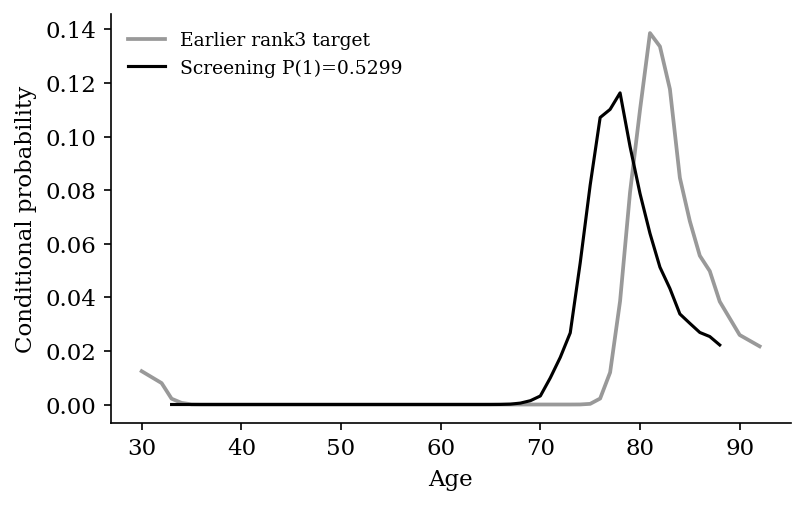

### Higher-P(1) #2: config072_p
Screening P(1)=0.5457; TV=0.5371; correlation=0.9688.

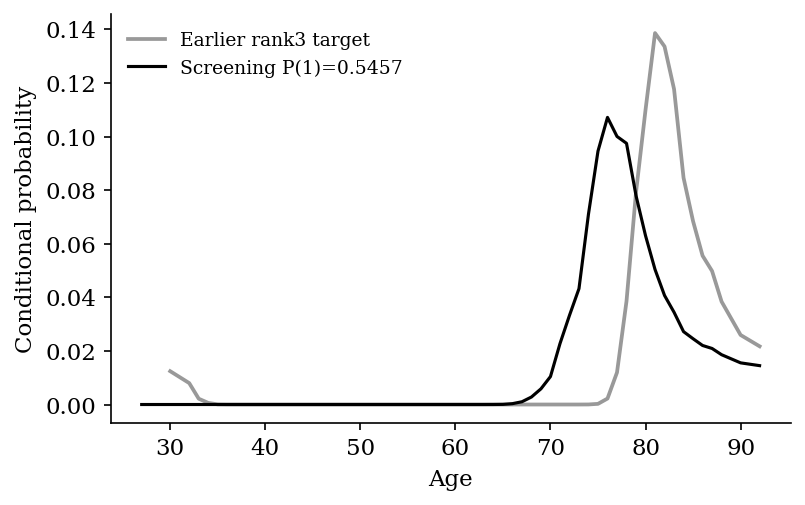

### Higher-P(1) #3: config184_p
Screening P(1)=0.5622; TV=0.5409; correlation=0.9670.

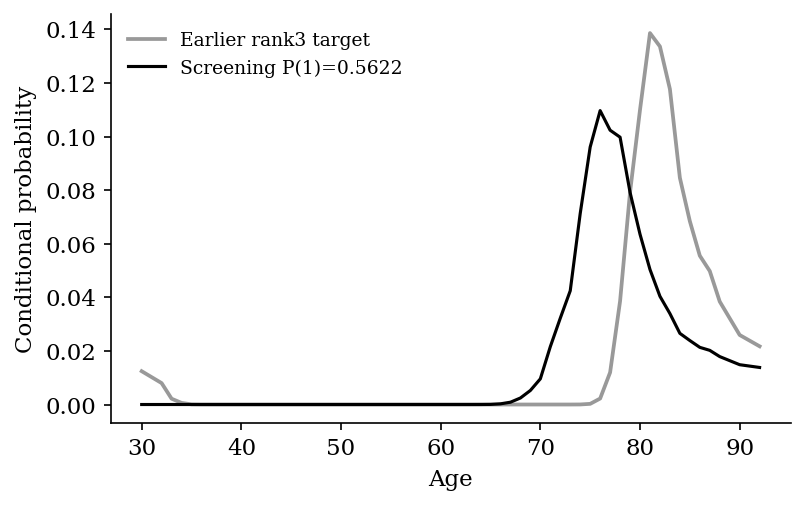

### Higher-P(1) #4: config188_p
Screening P(1)=0.5238; TV=0.5493; correlation=0.9668.

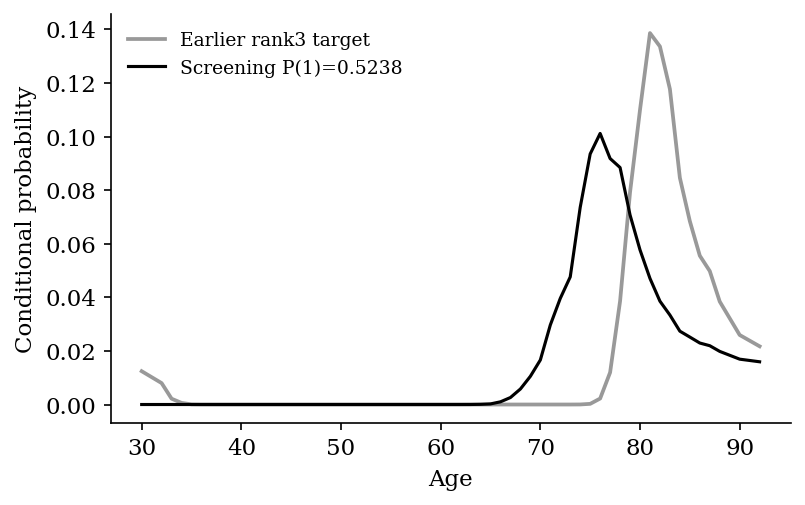

### Higher-P(1) #5: config076_p
Screening P(1)=0.5131; TV=0.5497; correlation=0.9685.

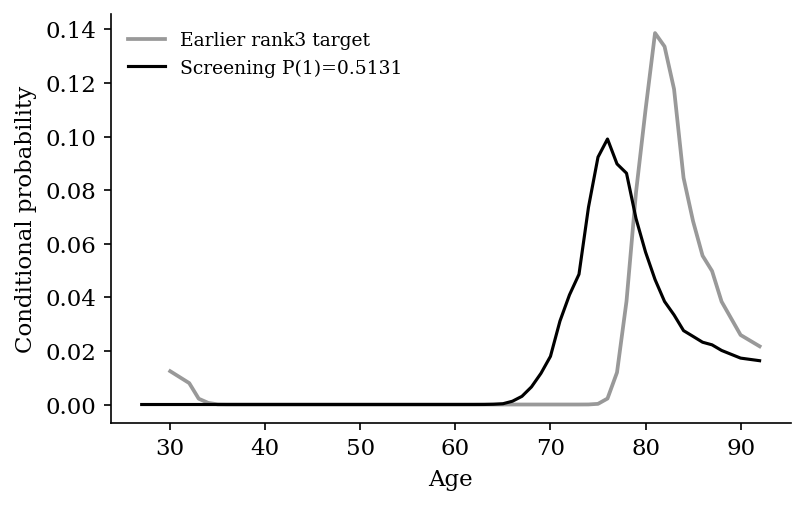

### Higher-P(1) #6: config080_p
Screening P(1)=0.5032; TV=0.5667; correlation=0.9688.

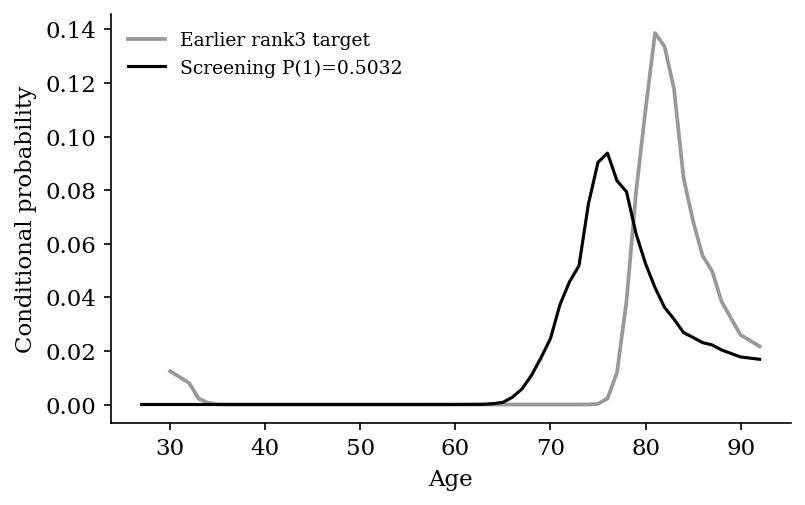

### Higher-P(1) #7: config192_p
Screening P(1)=0.5149; TV=0.5674; correlation=0.9670.

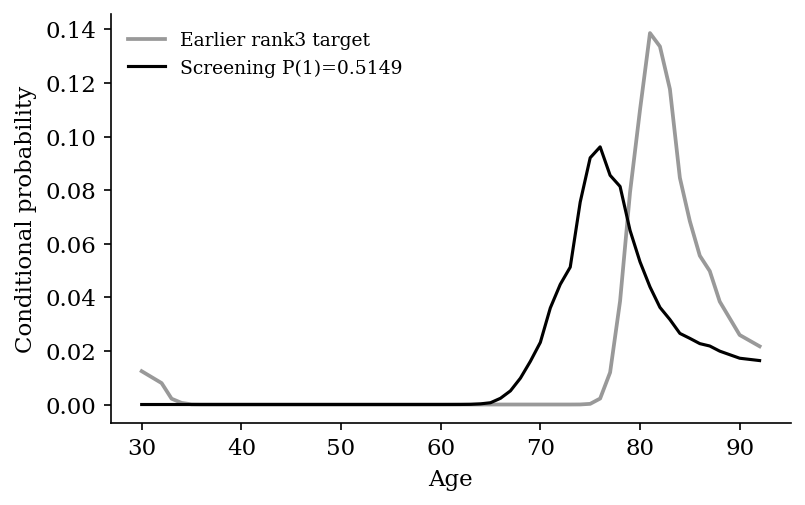

### Higher-P(1) #8: config300_p
Screening P(1)=0.5580; TV=0.5742; correlation=0.9622.

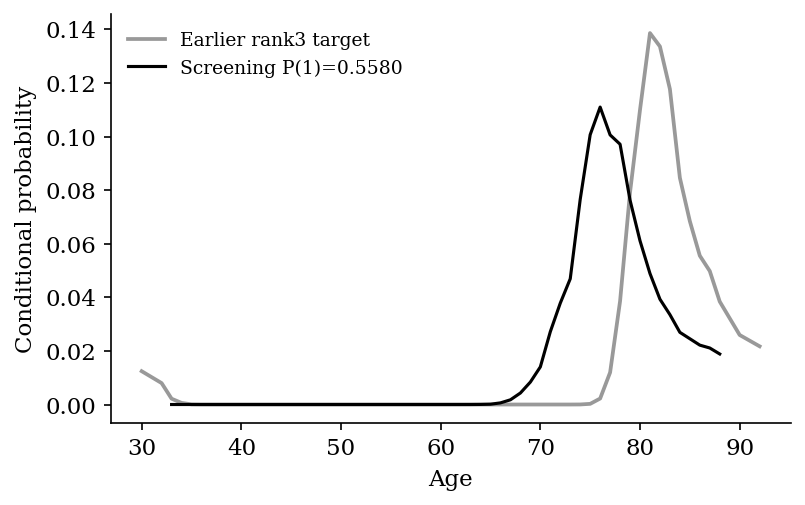

### Higher-P(1) #9: config296_p
Screening P(1)=0.6069; TV=0.5743; correlation=0.9624.

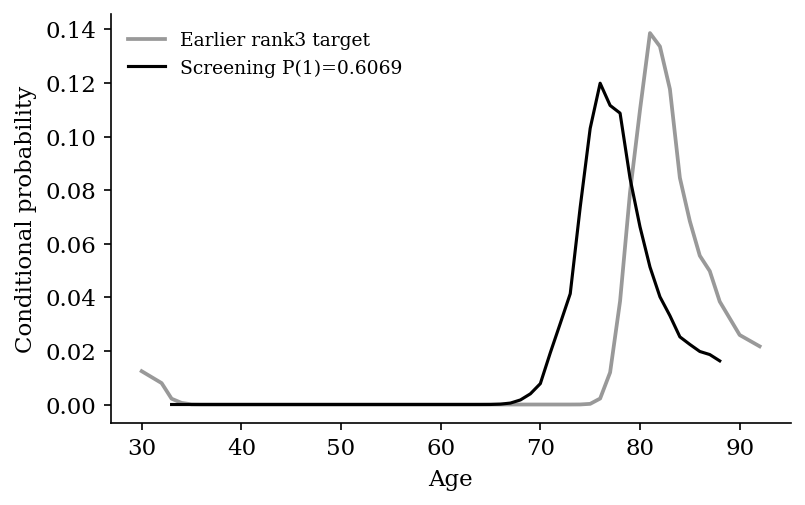

### Higher-P(1) #10: config304_p
Screening P(1)=0.5534; TV=0.5977; correlation=0.9624.

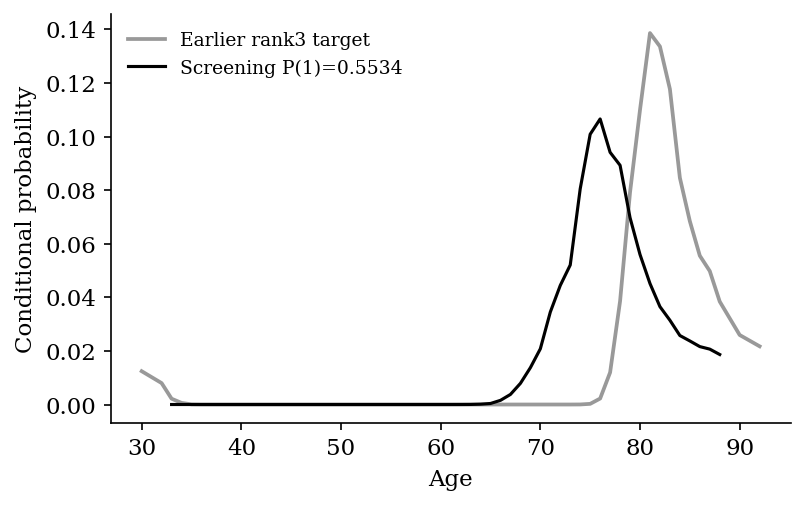

In [1]:

from pathlib import Path
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=Path('results/myocardial_gram_pair_1ce06b10b4f5/whole')
summary=pd.read_csv(root/'summary.csv')
selected=summary.loc[summary.P_1>=0.5].sort_values('TV_to_rank3').head(10).copy()
selected.insert(0,'subset_rank',range(1,len(selected)+1))
validation=pd.read_csv(root/'validation.csv')
checks=validation.groupby('id').agg(recheck_P1_min=('P_1','min'),recheck_P1_max=('P_1','max'),recheck_count=('P_1','size'))
selected=selected.merge(checks,left_on='id',right_index=True,how='left')
selected['recheck_count']=selected.recheck_count.fillna(0).astype(int)
cols=['subset_rank','id','P_1','TV_to_rank3','aux_loss','penalty','strength','method','budget','intercept','Delta','denominator','correlation','peak_age','mass_above55','recheck_count','recheck_P1_min','recheck_P1_max']
display(selected[cols].style.hide(axis='index').format(precision=5,na_rep='Not rechecked'))
target=pickle.load(open('results/myocardial_final_redo_e3d965cc4b9b/scenario_100_100_q10_seed123.pkl','rb'))
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
for row in selected.itertuples():
    result=pickle.load(open(row.checkpoint,'rb'))
    display(Markdown(f'### Higher-P(1) #{row.subset_rank}: {row.id}\n'
        f'Screening P(1)={row.P_1:.4f}; TV={row.TV_to_rank3:.4f}; correlation={row.correlation:.4f}.'))
    fig,ax=plt.subplots(figsize=(5.5,3.5))
    ax.plot(target['ages'],target['conditional'],color='.6',lw=1.8,label='Earlier rank3 target')
    ax.plot(result['ages'],result['conditional'],color='black',lw=1.5,label=f'Screening P(1)={row.P_1:.4f}')
    for check in validation.loc[validation.id==row.id].itertuples():
        checked=pickle.load(open(check.checkpoint,'rb'))
        ax.plot(checked['ages'],checked['conditional'],lw=1,ls='--',alpha=.7,label=f'Recheck seed {check.seed}: P(1)={check.P_1:.4f}')
    ax.set(xlabel='Age',ylabel='Conditional probability')
    ax.legend(frameon=False,fontsize=9);fig.tight_layout();plt.show()
